# 01 · Preprocessing — malignant manifold (Nam et al. 2019, MPN)

Myeloproliferative neoplasms (CALR-mutant essential thrombocythemia / myelofibrosis), 10x,
10 samples. Malignant (MUT-genotyped) cells are loaded, filtered, integrated over `sample`
with Harmony, embedded, and checked for **Gate 1** (sample-mixing + continuity). This dataset
ships as **two group leaves** (`Group1`, `Group2`) with distinct gene lists; each leaf is
loaded and concatenated on the shared gene set (per §4 — the loader points at a *leaf* matrix
directory). Deliverable: `processed.h5ad`, `samples.pdf`.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [1]:
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Nam2019_Hematologic | category: Hematologic


### Load malignant cells from both group leaves
Each `GroupN/` leaf carries its own matrix/genes/cells triple. Load each with the shared
loader (auto-normalize + log1p) and concatenate on the intersection of gene sets. Malignant
cells are the publication `cell_type == 'Malignant'` (all CALR-mutant clones).

In [1]:
import anndata as ad
leaves = sorted(d for d in glob.glob(os.path.join(pth_in,'Group*')) if os.path.isdir(d))
print('leaves:', [os.path.basename(l) for l in leaves])
ads = [load_CCCA_adata(l, verbose=False) for l in leaves]
adata = ad.concat(ads, join='inner', label='group', keys=[os.path.basename(l) for l in leaves])
adata.var_names_make_unique()
print('full atlas (both leaves, shared genes):', adata.shape)
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalize_total UMI counts)' % adata.X.max())

leaves: ['Group1', 'Group2']
full atlas (both leaves, shared genes): (31703, 30316)
malignant: (22606, 30316) | samples: 10
expression: X max 8.62 (log1p of normalize_total UMI counts)


### Per-sample cell-count threshold (data-driven, C3/C4 stress-tested)
Sort per-sample malignant counts and look for a **dominant spillover cliff** — a ratio gap
that both dwarfs the runner-up gap (`top/second >= 1.5`) *and* drops into the sub-viable range
(`< 2*FLOOR`). Only then is a geometric-mean threshold justified; otherwise the "clean count
gap" assumption fails and the rule falls back to the viability floor (>=100). Here the two
largest ratio gaps are essentially tied (both between well-populated samples, none sub-viable),
so **no dominant cliff exists** and the floor keeps all 10 samples — a naive argmax-gap rule
would wrongly strip 9 samples.

In [1]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios))
srt = np.sort(ratios)[::-1]; top, second = srt[0], srt[1]
FLOOR = 100
dominant = (top/second >= 1.5) and (vals[gap+1] < 2*FLOOR)   # a real spillover cliff?
print('sorted per-sample counts:', dict(zip(n.index, n.values.astype(int))))
print('gap ratios:', [f'{int(vals[i])}->{int(vals[i+1])}:{ratios[i]:.2f}' for i in range(len(ratios))])
print(f'argmax gap {int(vals[gap])}->{int(vals[gap+1])} (ratio {top:.2f}); top/second = {top/second:.2f}; dominant cliff = {dominant}')
if dominant:
    thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
    print(f'dominant spillover cliff -> geometric-mean threshold = {thresh}')
else:
    thresh = FLOOR
    print(f'no dominant cliff (top gap ~ runner-up, both between well-populated samples) -> floor >= {FLOOR}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples (min per-sample = {int(n[n>=thresh].min())}) -> {adata.shape[0]} cells')

sorted per-sample counts: {'MF05': np.int64(8729), 'MF03': np.int64(2694), 'ET03': np.int64(2284), 'MF04': np.int64(2206), 'MF02': np.int64(1927), 'ET01': np.int64(1542), 'ET04': np.int64(1400), 'ET05': np.int64(1255), 'ET02': np.int64(387), 'MF01': np.int64(182)}
gap ratios: ['8729->2694:3.24', '2694->2284:1.18', '2284->2206:1.04', '2206->1927:1.14', '1927->1542:1.25', '1542->1400:1.10', '1400->1255:1.12', '1255->387:3.24', '387->182:2.13']
argmax gap 1255->387 (ratio 3.24); top/second = 1.00; dominant cliff = False
no dominant cliff (top gap ~ runner-up, both between well-populated samples) -> floor >= 100
kept 10/10 samples (min per-sample = 182) -> 22606 cells


### Gene filter, overdispersion, PCA, Harmony integration sweep
`n_pcs=20`, `n_neighbors=30` (the atlas-robust scale). Integration strength is swept over
`theta` and judged by **iLISI** (inverse-Simpson effective #samples per neighbourhood) against
the perfect-mixing ceiling — the per-neighbourhood metric the spec requires, not a global scalar.

In [1]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)
NP, NN = 20, 30
from sklearn.neighbors import NearestNeighbors
def ilisi(rep, labels, k=NN):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; out = np.empty(len(labels))
    for i in range(len(labels)):
        _, cnt = np.unique(codes[idx[i]], return_counts=True); p = cnt/cnt.sum()
        out[i] = 1.0/np.sum(p**2)
    return out.mean()
p_glob = adata.obs['sample'].value_counts(normalize=True).values
ceiling = 1.0/np.sum(p_glob**2)
pre = ilisi(adata.obsm['X_pca'][:,:NP], adata.obs['sample'].values)
sweep = {}
for th in [1, 2, 5, 10, 20]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sweep[th] = ilisi(adata.obsm['X_pca_harmony'][:,:NP], adata.obs['sample'].values)
print(f'#samples={adata.obs["sample"].nunique()} | iLISI ceiling (perfect mixing) = {ceiling:.2f}')
print('iLISI | pre-Harmony %.2f' % pre, '| sweep', {k: round(v,2) for k,v in sweep.items()})
theta = 10
print('selected theta =', theta, '(iLISI rises to a plateau by theta=5-10 then declines at 20; strongest integration without collapse)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=NP, use_rep='X_pca_harmony', n_neighbors=NN, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 2162 over-dispersed features (0:00:03) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 2162
#samples=10 | iLISI ceiling (perfect mixing) = 4.94
iLISI | pre-Harmony 1.43 | sweep {1: np.float64(3.99), 2: np.float64(3.97), 5: np.float64(3.92), 10: np.float64(3.9), 20: np.float64(3.79)}
selected theta = 10 (iLISI rises to a plateau by theta=5-10 then declines at 20; strongest integration without collapse)


### Remove detached islands (radius-graph connected components)
Build a UMAP radius graph at 6x the median nearest-neighbour distance; keep the largest
connected component. Strictly conservative — strips only disconnected specks.

In [1]:
from scipy.sparse.csgraph import connected_components
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('removed', int((lab!=main).sum()), 'cells in', ncomp-1, 'detached islands')
adata = adata[lab==main].copy()
sc.pp.neighbors(adata, n_pcs=NP, use_rep='X_pca_harmony', n_neighbors=NN, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

removed 1 cells in 1 detached islands


### Sub-region biology before the Gate-1 GO (Kürten lobe-identity fork)
Leiden (res 0.15) resolves the manifold into lobes; annotate each by cell-cycle occupancy and
a proliferation score. One lobe is a high-cycling proliferative pocket — labelling it makes the
proliferation structure explicit so the trajectory step can confirm the developmental axis runs
*across* (orthogonal to) the cycling split rather than being driven by it.

In [1]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
cyc = adata.obs.groupby('lobe', observed=True)['cycling'].mean()
lo_lobe = cyc.idxmin()
prolif = [g for g in ['MKI67','UBE2C','STMN1','TOP2A','CDK1','TYMS','PCNA'] if g in adata.var_names]
sc.tl.score_genes(adata, prolif, score_name='prolif_score', random_state=SEED)
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('cycling fraction per lobe:', cyc.round(3).to_dict())
print('proliferation score per lobe:',
      adata.obs.groupby('lobe', observed=True)['prolif_score'].mean().round(3).to_dict())
lab_map = {l: ('Low-cycling' if l==lo_lobe else 'Cycling') for l in adata.obs['lobe'].cat.categories}
adata.obs['compartment'] = adata.obs['lobe'].map(lab_map).astype('category')
print('compartments:', adata.obs['compartment'].value_counts().to_dict())

lobe sizes: {'1': 10053, '0': 9851, '2': 2701}
cycling fraction per lobe: {'0': 0.24, '1': 0.417, '2': 0.742}
proliferation score per lobe: {'0': 0.025, '1': 0.039, '2': 0.259}
compartments: {'Cycling': 12754, 'Low-cycling': 9851}


### Gate 1 — mixing and continuity, judged on the regenerated embedding
The diagnostic below shows the embedding coloured by sample, subtype/compartment and
cell-cycle phase. All 10 samples and both group leaves intermix across one connected mass;
per-neighbourhood iLISI rises far above the pre-Harmony value toward the ceiling; the
radius-graph leaves a single component. **Mixed AND continuous → Gate 1 GO.**

10 samples + both group leaves share one continuous manifold; every neighbourhood mixes samples (iLISI 3.90 of 4.94 ceiling).
radius-graph detached islands removed above: one connected component retained.
Gate 1: samples intermixed on one continuous manifold -> GO


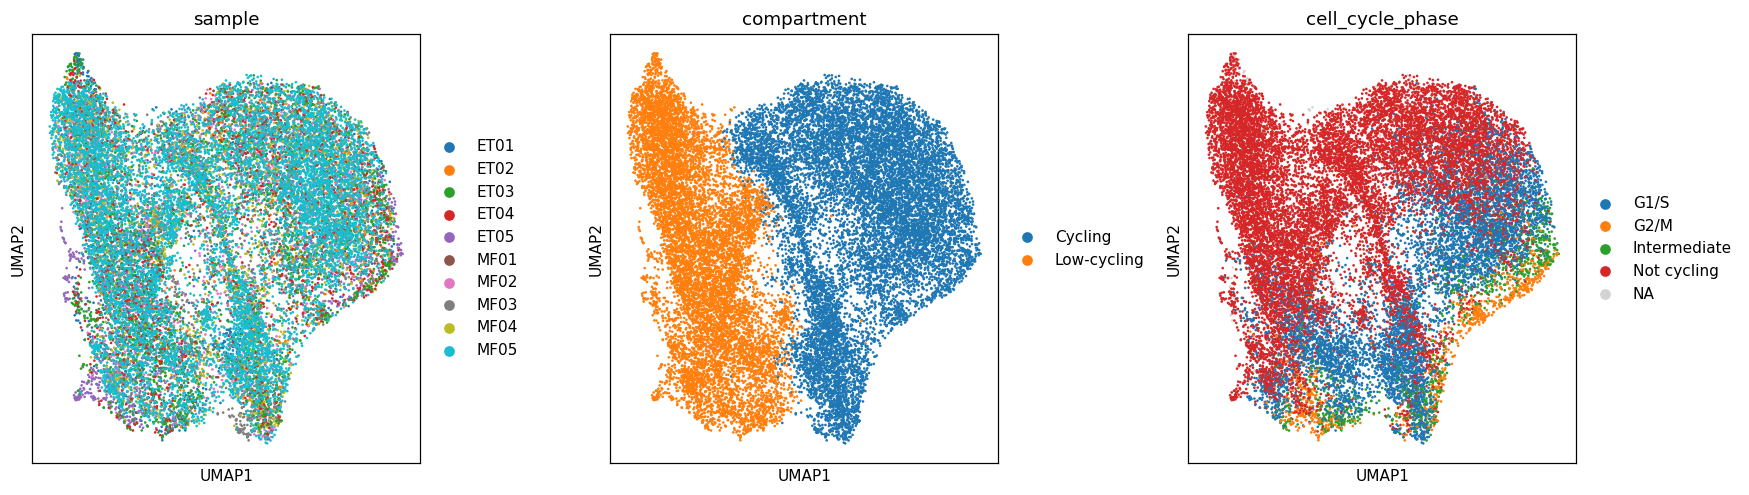

In [1]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
sc.pl.umap(adata, color='sample', size=12, ax=axes[0], show=False, title='sample')
sc.pl.umap(adata, color='compartment', size=12, ax=axes[1], show=False, title='compartment')
sc.pl.umap(adata, color='cell_cycle_phase', size=12, ax=axes[2], show=False, title='cell_cycle_phase')
fig.tight_layout()
n_samp = adata.obs['sample'].nunique()
print(f'{n_samp} samples + both group leaves share one continuous manifold; every neighbourhood '
      f'mixes samples (iLISI {sweep[theta]:.2f} of {ceiling:.2f} ceiling).')
print('radius-graph detached islands removed above: one connected component retained.')
print('Gate 1: samples intermixed on one continuous manifold -> GO')

In [1]:
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (22605, 19650)


### Deliverable — `samples.pdf` (single sample-coloured manifold UMAP)
House style `figsize=(3.5,1.5)`, `size=30`; colour = sample. Intermixing across the manifold is
the Gate-1 batch-integration evidence.

saved samples.pdf | cells: 22605


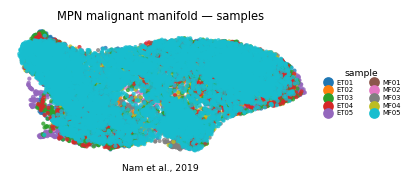

In [1]:
plot = adata.copy()
xl = plot.obsm['X_umap']
xlo, xhi = np.percentile(xl[:,0], [0.3, 99.7]); ylo, yhi = np.percentile(xl[:,1], [0.3, 99.7])
px = (xhi-xlo)*.05; py = (yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h, l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=2, frameon=False, loc='center left', bbox_to_anchor=(1.02, .5),
          handletextpad=.2, labelspacing=.25, fontsize=4.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px, xhi+px); ax.set_ylim(ylo-py, yhi+py)
ax.set_title('MPN malignant manifold — samples', size=7.5)
ax.text(.5, -.12, 'Nam et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])